# Pakistan SMS classification dataset

SMS messages labelled Normal / Promotional / fraud, from Kaggle
(https://www.kaggle.com/datasets/muhammadhumyun/pakistan-sms-classification-dataset).

It's text, so the plan is: check label balance, clean up the obvious mess, look at message length,
duplicates and templates, what patterns (links, phone numbers, money, urgency) go with each class,
and then a small TF-IDF baseline at the end to see how separable the classes are.

Phone numbers in printed examples are masked (digits replaced with X). The data itself is left as is.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_colwidth', 160)
pd.set_option('display.width', 200)

plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 150, 'font.size': 11,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
Path('charts').mkdir(exist_ok=True)

labels = ['Normal', 'Promotional', 'Fraud']
colors = {'Normal': '#2a78d6', 'Promotional': '#eb6834', 'Fraud': '#1baf7a'}

def save(name):
    plt.tight_layout()
    plt.savefig(f'charts/{name}.png', bbox_inches='tight')
    plt.show()

def mask(s):
    # hide anything that looks like a phone / account / ID number
    return re.sub(r'\d(?:[\d\-\s]{5,}\d)', lambda m: re.sub(r'\d', 'X', m.group()), str(s))

## Load and first look

In [2]:
raw = pd.read_csv('Pakistan_sms_dataset.csv')
print(raw.shape)
print(raw.dtypes)
print(raw.isna().sum())
raw.head(5).assign(Messages=lambda d: d.Messages.map(mask), clean_message=lambda d: d.clean_message.map(mask))

(4895, 3)
Label            str
Messages         str
clean_message    str
dtype: object
Label            0
Messages         0
clean_message    0
dtype: int64


,Label,Messages,clean_message
0,fraud,"Telenor customer your prize is 5 lakh 1 bike 1 freezer, call XXXXXXXXXX,",telenor customer your prize is 5 lakh 1 bike 1 freezer call XXXXXXXXXX
1,fraud,"Dear Telenor customer, your prize is out. For information, call XXXXXXXXXX.",dear telenor customer your prize is out for information call XXXXXXXXXX
2,fraud,"75600 from Benazir Program Congratulations. for further Information, WhatsApp XXXXXXXXXX",75600 from benazir program congratulations for further information whatsapp XXXXXXXXXX
3,fraud,"15600 from Benazir Program Congratulations., please call XXXXXXXXXX",15600 from benazir program congratulations please call XXXXXXXXXX
4,fraud,"In the ARY JEETO PAKISTAN show, your number XXXXXXX is selected in the lucky draw. you have won a 2 lakh rupees cheque.3-gram gold. 1 laptop. contact me on ...",in the ary jeeto pakistan show your number XXXXXXX is selected in the lucky draw you have won a 2 lakh rupees cheque3gram gold 1 laptop contact me on whatsa...


Three columns: the label, the raw message, and a `clean_message` the uploader already made
(lowercased, punctuation stripped). No missing values. No data dictionary came with the file.

In [3]:
print(raw.Label.value_counts())
print()
print('fully duplicated rows:', raw.duplicated().sum())
print('duplicated Messages:', raw.Messages.duplicated().sum())
print('duplicated clean_message:', raw.clean_message.duplicated().sum())

# is the file ordered by label?
runs = raw.Label.ne(raw.Label.shift()).cumsum()
print(raw.groupby(runs).agg(label=('Label', 'first'), rows=('Label', 'size'), first_row=('Label', lambda s: s.index[0])))

Label
Normal         2504
Promotional    1280
fraud          1111
Name: count, dtype: int64

fully duplicated rows: 0
duplicated Messages: 1
duplicated clean_message: 4
             label  rows  first_row
Label                              
1            fraud  1111          0
2      Promotional  1280       1111
3           Normal  2504       2391


The file is sorted by label in three solid blocks (fraud, then Promotional, then Normal), so anything
that splits by row order would be badly wrong. Label casing is inconsistent (`fraud` vs the other two).

A few odd things to check before cleaning: wrapping quote marks, broken characters, and anything that
isn't actually an SMS.

In [4]:
m = raw.Messages
quoted = m.str.match(r'^\s*["\u201c]')
print('share of messages wrapped in quote marks, by label')
print(quoted.groupby(raw.Label).agg(['sum', 'mean']).round(3))

print()
print('leading/trailing whitespace:', (m != m.str.strip()).sum())
print('messages with non-ASCII characters:', m.str.contains(r'[^\x00-\x7f]').sum())
print('messages in Arabic/Urdu script:', m.str.contains(r'[\u0600-\u06ff]').sum())
print('messages with mojibake (Â, Ã, â€, ï¿½):', m.str.contains('Â|Ã|â€|ï¿½').sum())
chars = pd.Series(list(''.join(m)))
print(chars[chars.map(ord) > 127].value_counts().head(8).to_dict())

share of messages wrapped in quote marks, by label
              sum   mean
Label                   
Normal       2283  0.912
Promotional   903  0.705
fraud          39  0.035

leading/trailing whitespace: 26
messages with non-ASCII characters: 272
messages in Arabic/Urdu script: 0
messages with mojibake (Â, Ã, â€, ï¿½): 50


{'—': 135, '£': 107, 'Â': 59, '–': 30, '’': 10, 'å': 9, 'ï': 4, '¿': 4}


In [5]:
# rows that are chatbot chatter rather than messages
leftover = m.str.contains(r'(?i)here are \d+ (?:more |unique )?variations|^certainly|^sure[,!]|as an ai')
raw[leftover]

,Label,Messages,clean_message
404,fraud,"Certainly, here are 50 unique variations of the message with different WhatsApp numbers and cash amounts:",certainly here are 50 unique variations of the message with different whatsapp numbers and cash amounts
4556,Normal,And here are 10 more variations:,and here are 10 more variations


Things noticed:

- 91% of Normal and 71% of Promotional messages are wrapped in literal double quotes, against under 4% of
  fraud. That is an artefact of how the rows were produced, not a property of SMS, and a model given the
  raw text could use the quote mark alone to guess the class.
- Two rows are not messages at all. They are leftover chatbot replies ("Certainly, here are 50 unique
  variations of the message...", "And here are 10 more variations"). So at least part of this dataset was
  written by an LLM asked to paraphrase seed messages.
- There is no Urdu script anywhere. The non-ASCII characters are dashes, pound signs and some
  encoding damage (`Â£`).

## Cleaning

In [6]:
df = raw.rename(columns={'Label': 'label', 'Messages': 'message'}).copy()

# consistent label casing
df['label'] = df.label.str.strip().str.capitalize()

# drop the two chatbot leftovers, they are not SMS
df = df[~leftover].copy()

# remember which rows were quote-wrapped, then strip the wrapping quotes and stray whitespace
df['was_quoted'] = df.message.str.match(r'^\s*["\u201c]')
df['text'] = (df.message.str.strip()
                .str.replace(r'^["\u201c\u201d]+|["\u201c\u201d]+$', '', regex=True)
                .str.strip())

# repair encoding damage: 'Â£' is a pound sign read with the wrong codec
def fix_enc(s):
    if re.search('Â|Ã|â€', s):
        try:
            return s.encode('cp1252').decode('utf-8')
        except (UnicodeEncodeError, UnicodeDecodeError):
            return s.replace('Â£', '£').replace('Â', '')
    return s
before = df.text.copy()
df['text'] = df.text.map(fix_enc).str.replace('ï¿½', '', regex=False).str.replace(r'\s+', ' ', regex=True).str.strip()
print('rows changed by encoding/whitespace repair:', (before != df.text).sum())
print('still containing Â/Ã:', df.text.str.contains('Â|Ã').sum())

# normalised key for duplicate checks (the shipped clean_message keeps curly quotes and double spaces)
df['text_norm'] = (df.text.str.lower()
                     .str.replace(r'[^a-z0-9\s]', '', regex=True)
                     .str.replace(r'\s+', ' ', regex=True).str.strip())
print('empty after normalising:', (df.text_norm == '').sum())

rows changed by encoding/whitespace repair: 77
still containing Â/Ã: 0
empty after normalising: 0


In [7]:
dups = df[df.text_norm.duplicated(keep=False)].sort_values('text_norm')
print('rows involved in exact duplicates (after normalising):', len(dups))
dups[['label', 'text']].assign(text=lambda d: d.text.map(mask))

rows involved in exact duplicates (after normalising): 14


,label,text
683,Fraud,Card Security Issue: Your ATM card has been blocked due to incomplete biometric verification. Contact us at XXXXXXXXXXX to restore access.
690,Fraud,Card Security Issue: Your ATM card has been blocked due to incomplete biometric verification. Contact us at XXXXXXXXXXX to restore access
168,Fraud,"Dear customer your PayPal has been expired, It will be blocked within 24 hours, please contact us!call on our XXXXXXXXXX"
1159,Promotional,"Dear customer your PayPal has been expired, It will be blocked within 24 hours, please contact us!call on our XXXXXXXXXX"
2394,Normal,Finished class where are you.
2680,Normal,"Finished class, where are you?"
3983,Normal,Sending you smiles for every moment of your special day... Have a wonderful time and a very Happy Birthday!
3996,Normal,Sending you smiles for every moment of your special day. Have a wonderful time and a very Happy Birthday!
102,Fraud,"Thank you, winner notified by sms. Good Luck! No future marketing reply STOP to 84122 customer services XXXXXXXXXXX"
1205,Promotional,"Thank you, winner notified by sms. Good Luck! No future marketing reply STOP to 84122 customer services XXXXXXXXXXX"


In [8]:
# a couple of messages appear under two different labels; the label is ambiguous so both copies go
n_lab = df.groupby('text_norm').label.transform('nunique')
print('rows with a conflicting label:', (n_lab > 1).sum())
df = df[n_lab == 1]

# for the rest keep the first copy
n0 = len(df)
df = df.drop_duplicates('text_norm').reset_index(drop=True)
print('same-label duplicates dropped:', n0 - len(df))

df['n_chars'] = df.text.str.len()
df['n_words'] = df.text.str.split().str.len()
print('raw rows:', len(raw), '-> cleaned rows:', len(df))
print(df.label.value_counts())

rows with a conflicting label: 4


same-label duplicates dropped: 5
raw rows: 4895 -> cleaned rows: 4884
label
Normal         2501
Promotional    1276
Fraud          1107
Name: count, dtype: int64


Cleaning summary, and why:

- label casing standardised (`fraud` -> `Fraud`)
- 2 chatbot leftover rows removed, since they are not messages
- wrapping quote marks stripped, because they track the label and would leak it; a `was_quoted` flag is kept
- encoding damage repaired so `Â£` reads as `£`
- exact duplicates removed after normalising; the two messages that each appeared under two different labels (4 rows) were dropped entirely
- no outlier removal on length: the long messages are real-looking adverts, not errors

The shipped `clean_message` column is left untouched in the output for reference.

## Label balance and message length

             messages  share_pct
label                           
Normal           2501       51.2
Promotional      1276       26.1
Fraud            1107       22.7


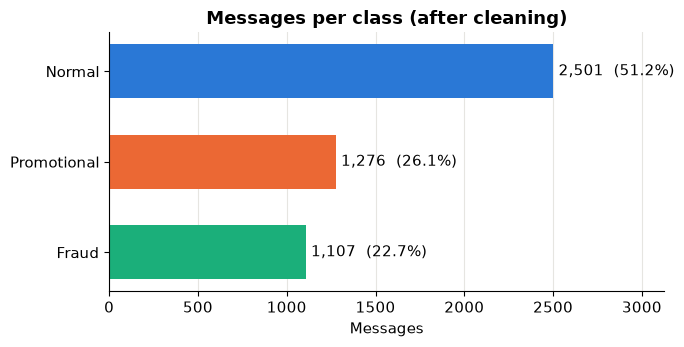

In [9]:
counts = df.label.value_counts().reindex(labels)
share = (counts / len(df) * 100).round(1)
print(pd.DataFrame({'messages': counts, 'share_pct': share}))

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.barh(labels[::-1], counts[labels[::-1]], color=[colors[l] for l in labels[::-1]], height=0.6)
for b, l in zip(bars, labels[::-1]):
    ax.text(b.get_width() + 30, b.get_y() + b.get_height() / 2, f'{counts[l]:,}  ({share[l]}%)', va='center')
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel('Messages')
ax.set_title('Messages per class (after cleaning)')
ax.grid(axis='y', visible=False)
save('01_label_counts')

In [10]:
length_stats = df.groupby('label')[['n_chars', 'n_words']].describe().round(1).loc[labels]
print(length_stats['n_chars'])
print(length_stats['n_words'])
print('messages over 160 characters (one SMS segment):')
print((df.n_chars > 160).groupby(df.label).mean().mul(100).round(1).reindex(labels))

              count   mean   std   min    25%    50%    75%    max
label                                                             
Normal       2501.0   76.1  25.5  12.0   60.0   71.0   91.0  289.0
Promotional  1276.0  152.3  61.1  29.0  103.8  155.0  187.0  582.0
Fraud        1107.0  146.4  27.6  48.0  130.0  144.0  162.0  322.0
              count  mean  std  min   25%   50%   75%    max
label                                                       
Normal       2501.0  13.3  4.7  2.0  10.0  12.0  16.0   55.0
Promotional  1276.0  23.9  9.5  5.0  17.0  23.0  29.0  101.0
Fraud        1107.0  24.2  5.3  7.0  21.0  23.0  27.0   52.0
messages over 160 characters (one SMS segment):
label
Normal          0.3
Promotional    43.5
Fraud          27.0
Name: n_chars, dtype: float64


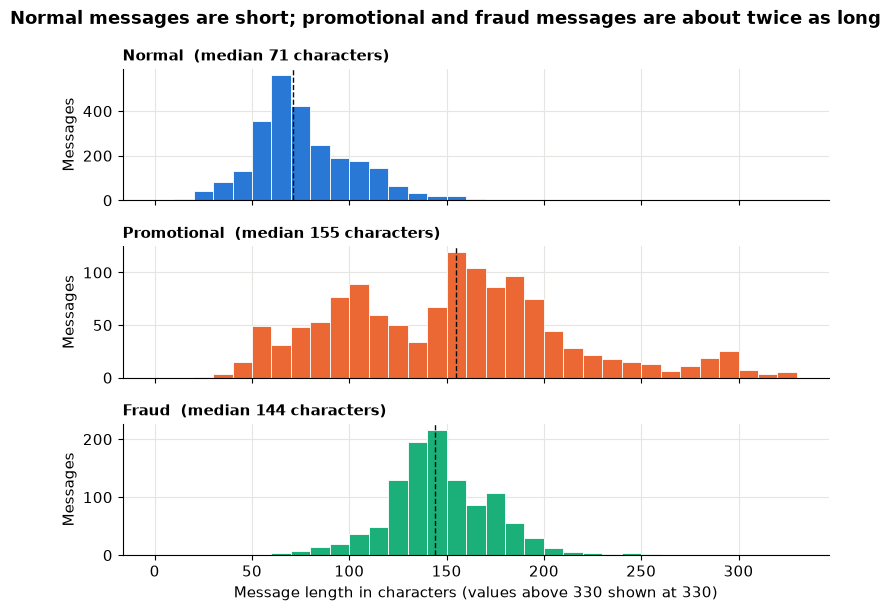

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(8, 6.2), sharex=True)
bins = np.arange(0, 340, 10)
for ax, l in zip(axes, labels):
    x = df.loc[df.label == l, 'n_chars'].clip(upper=330)
    ax.hist(x, bins=bins, color=colors[l], edgecolor='white', linewidth=0.6)
    med = df.loc[df.label == l, 'n_chars'].median()
    ax.axvline(med, color='#0b0b0b', linewidth=1, linestyle='--')
    ax.set_title(f'{l}  (median {med:.0f} characters)', loc='left', fontsize=11)
    ax.set_ylabel('Messages')
axes[-1].set_xlabel('Message length in characters (values above 330 shown at 330)')
fig.suptitle('Normal messages are short; promotional and fraud messages are about twice as long', fontweight='bold', fontsize=13)
save('02_length_by_class')

Normal messages sit in a tight band around 70 characters. Fraud messages are also tightly bunched, but
around 145, and promotional ones are spread widest. The narrow fraud distribution is the first hint that
many of them come from the same few templates.

## Are these real messages? Sources and templates

In [12]:
t = df.text
low = t.str.lower()
digits = t.str.replace(r'(?<=\d)[\s\-](?=\d)', '', regex=True)

# rough origin markers
df['uk_style'] = (t.str.contains('£') | low.str.contains(r'\b\d+p\b|\bppm\b|\bt&cs?\b|\bpo box\b')
                  | digits.str.contains(r'\b0[89]\d{9}\b'))
pk_words = (r'\brs\b|rupees?|\blakh|\blac\b|\bpkr\b|pakistan|benazir|\bbisp\b|8171|telenor|jazz|zong|ufone|easypaisa|'
            r'karachi|lahore|islamabad|peshawar|rawalpindi|daraz|\bhbl\b|whatsapp')
df['pk_marker'] = low.str.contains(pk_words) | digits.str.contains(r'(?<!\d)(?:\+?92|0)?3[0-4]\d{8}(?!\d)')
df['txt_speak'] = low.str.contains(r'\b(?:u|ur|r|2|4|wat|lor|liao|dun|wif|thk|pls|msg|txt|b4|gd|da)\b')

src = df.groupby('label')[['was_quoted', 'uk_style', 'pk_marker', 'txt_speak']].mean().mul(100).round(1).loc[labels]
print(src)
print()
print('overall:', df[['was_quoted', 'uk_style', 'pk_marker', 'txt_speak']].mean().mul(100).round(1).to_dict())

             was_quoted  uk_style  pk_marker  txt_speak
label                                                  
Normal             91.2       0.0        0.0        2.1
Promotional        70.8      12.0       30.5       10.0
Fraud               3.5       7.5       79.9        7.3

overall: {'was_quoted': 66.0, 'uk_style': 4.8, 'pk_marker': 26.1, 'txt_speak': 5.3}


In [13]:
# quoted vs unquoted rows look like two different sources
print(df.groupby(['label', 'was_quoted']).agg(rows=('text', 'size'), median_chars=('n_chars', 'median'),
                                              txt_speak=('txt_speak', 'mean'), uk_style=('uk_style', 'mean')).round(2))
for l in labels:
    for q in [False, True]:
        s = df[(df.label == l) & (df.was_quoted == q)]
        if len(s):
            print(f'--- {l}, quoted={q}')
            for x in s.text.sample(min(4, len(s)), random_state=3):
                print('   ', mask(x)[:170])

                        rows  median_chars  txt_speak  uk_style
label       was_quoted                                         
Fraud       False       1068         143.0       0.08      0.08
            True          39         169.0       0.00      0.03
Normal      False        220          52.0       0.24      0.00
            True        2281          72.0       0.00      0.00
Promotional False        373         157.0       0.33      0.36
            True         903         153.0       0.00      0.02
--- Normal, quoted=False
    Lol no ouch but wish i'd stayed out a bit longer
    Oh k...i'm watching here:)
    How many licks does it take to get to the center of a tootsie pop?
    I dont know why she.s not getting your messages
--- Normal, quoted=True
    Brushing up on my geography knowledge as I plan my upcoming road trip.
    A few moments back, I was standing by, eagerly awaiting your arrival.
    Exploring new cuisines while studying anthropology. Food is a language of its o

Reading the samples, there look to be three kinds of row mixed together:

1. Short, messy, old-style texts with abbreviations, UK premium numbers, pound prices and "150p" tariffs.
   These read like a legacy English-language SMS spam corpus (UK and Singapore flavoured), not Pakistani SMS.
   I can't confirm the exact source from the file, so treat that as a strong impression, not a fact.
2. Pakistan-specific scam and promo messages (Benazir Income Support Programme, Jeeto Pakistan, telecom
   lucky draws, ATM card blocks). Some of these read like genuine collected messages.
3. Clean, grammatical, polished sentences in quote marks, often in runs of rewordings of the same idea.
   Together with the two chatbot leftovers found earlier, these are almost certainly LLM-written paraphrases.

Next: how much of the data is templated.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse.csgraph import connected_components

# skeleton = message with every number swapped for '#'
df['skeleton'] = df.text_norm.str.replace(r'\d+', '#', regex=True)
skel_size = df.groupby('skeleton').skeleton.transform('size')
print('rows sharing an identical skeleton with another row (same words, different numbers):')
print((skel_size > 1).groupby(df.label).agg(['sum', 'mean']).round(3).reindex(labels))

# near-duplicates: cosine similarity on word 1-2 gram TF-IDF of the skeleton
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X = vec.fit_transform(df.skeleton)
sim = (X @ X.T).tocsr()
sim.data[sim.data < 0.8] = 0
sim.eliminate_zeros()
n_groups, grp = connected_components(sim, directed=False)
df['dup_group'] = grp
grp_size = df.groupby('dup_group').dup_group.transform('size')
df['in_near_dup_group'] = grp_size > 1

print()
print('near-duplicate groups (cosine >= 0.8, linked):', n_groups, 'groups for', len(df), 'messages')
near = df.groupby('label').in_near_dup_group.agg(['sum', 'mean']).round(3).reindex(labels)
print(near)
print('overall share in a near-duplicate group:', round(df.in_near_dup_group.mean() * 100, 1))
print('groups that mix labels:', (df.groupby('dup_group').label.nunique() > 1).sum())

rows sharing an identical skeleton with another row (same words, different numbers):
             sum   mean
label                  
Normal         0  0.000
Promotional    4  0.003
Fraud        298  0.269



near-duplicate groups (cosine >= 0.8, linked): 4415 groups for 4884 messages
             sum   mean
label                  
Normal       169  0.068
Promotional   61  0.048
Fraud        447  0.404
overall share in a near-duplicate group: 13.9
groups that mix labels: 2


In [15]:
big = (df.groupby('dup_group').agg(size=('text', 'size'), label=('label', 'first'), example=('text', 'first'))
         .sort_values('size', ascending=False).head(10))
big['example'] = big.example.map(mask).str[:140]
big

,size,label,example
dup_group,,,
687,13,Fraud,Your remarkable accomplishments are a testament to your dedication. The Benazir Income Support Program is delighted to offer you a cash priz
686,13,Fraud,Your dedication and hard work have paid off splendidly. The Benazir Income Support Program is excited to award you a cash prize of 17950 rup
685,13,Fraud,Your journey towards success has been commendable. The Benazir Income Support Program takes pride in rewarding you with a cash prize of 2270
682,13,Fraud,Warmest greetings! Your accomplishments have not gone unnoticed. The Benazir Income Support Program is pleased to present you with a cash pr
690,12,Fraud,Your accomplishments have earned you this recognition. The Benazir Income Support Program is excited to present you with a cash prize of 178
689,12,Fraud,Congratulations on your remarkable journey! The Benazir Income Support Program takes pride in awarding you a cash prize of 23500 rupees as a
688,12,Fraud,Your perseverance and commitment have led you to this moment. The Benazir Income Support Program is thrilled to award you a cash prize of 18
627,11,Fraud,Well deserved! A cash prize of 15800 rupees has been awarded to you by the Benazir Income Support Program to celebrate your achievements.
602,10,Fraud,Wonderful achievement! The Benazir Income Support Program is pleased to grant you a cash prize of 21000 rupees as a token of your success.


             Wrapped in quote marks  In a near-duplicate group  UK-style markers (£, 08/09 numbers, "150p")  Pakistan markers (Rs, PK brands, 03xx numbers)
label                                                                                                                                                      
Normal                         91.2                        6.8                                          0.0                                             0.0
Promotional                    70.8                        4.8                                         12.0                                            30.5
Fraud                           3.5                       40.4                                          7.5                                            79.9


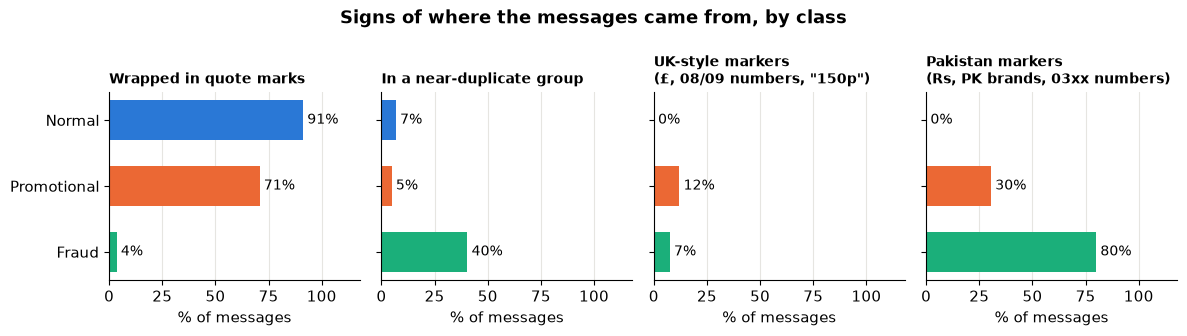

In [16]:
chart = pd.DataFrame({
    'Wrapped in quote marks': df.groupby('label').was_quoted.mean(),
    'In a near-duplicate group': df.groupby('label').in_near_dup_group.mean(),
    'UK-style markers (£, 08/09 numbers, "150p")': df.groupby('label').uk_style.mean(),
    'Pakistan markers (Rs, PK brands, 03xx numbers)': df.groupby('label').pk_marker.mean(),
}).mul(100).loc[labels]
print(chart.round(1))

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
for ax, col in zip(axes, chart.columns):
    b = ax.barh(labels[::-1], chart[col][labels[::-1]], color=[colors[l] for l in labels[::-1]], height=0.6)
    for r, l in zip(b, labels[::-1]):
        ax.text(r.get_width() + 2, r.get_y() + r.get_height() / 2, f'{chart.loc[l, col]:.0f}%', va='center', fontsize=10)
    ax.set_xlim(0, 118)
    ax.set_title(col.replace(' (', '\n('), fontsize=10, loc='left')
    ax.set_xlabel('% of messages')
    ax.grid(axis='y', visible=False)
fig.suptitle('Signs of where the messages came from, by class', fontweight='bold', fontsize=13)
save('03_provenance_markers')

The classes also differ in how they were assembled. Four in ten fraud rows
sit in a tight near-duplicate group (and that is a floor, since looser rewordings fall under the 0.8 cut),
nine in ten Normal rows are quote-wrapped generated-looking sentences, and a slice of the promotional and
fraud rows are UK-style spam. Worth keeping in mind for everything below.

## Patterns: links, numbers, money, urgency

In [17]:
df['has_url'] = low.str.contains(r'https?://|www\.|\b[a-z0-9\-]+\.(?:com|pk|net|org|ly|co|gl)\b')
df['has_phone'] = digits.str.contains(r'(?<!\d)\+?\d{10,13}(?!\d)')
df['has_pk_mobile'] = digits.str.contains(r'(?<!\d)(?:\+?92|0)?3[0-4]\d{8}(?!\d)')
df['has_shortcode'] = low.str.contains(r'\*\d+[\d\*]*#') | low.str.contains(r'\b(?:to|dial|sms|text|txt|send)\s+\d{3,5}\b')
df['has_money'] = low.str.contains(r'\brs\.?\s?\d|\d[\d,]*\s*(?:rupees|rs\b|lakh|lac\b|lack\b|pkr|crore)|£\s?\d|\$\s?\d|\bpkr\b|rupees')
df['has_prize_word'] = low.str.contains(r'congrat|\bwon\b|\bwin\b|winner|prize|lucky draw|reward|award|selected|cash')
df['has_urgency'] = low.str.contains(r'urgent|immediately|hurry|\bnow\b|today|limited|expire|last chance|asap|deadline|blocked|suspended|don.t miss|final notice')
df['has_discount'] = low.str.contains(r'\d+\s?%|\boff\b|discount|\bsale\b|offer|free\b')
df['has_hashtag'] = t.str.contains(r'#[A-Za-z]\w+')
df['has_whatsapp'] = low.str.contains('whatsapp')

flags = ['has_phone', 'has_pk_mobile', 'has_url', 'has_shortcode', 'has_money', 'has_prize_word',
         'has_urgency', 'has_discount', 'has_hashtag', 'has_whatsapp']
rates = df.groupby('label')[flags].mean().mul(100).round(1).loc[labels].T
rates['all'] = df[flags].mean().mul(100).round(1)
print(rates)
print()
print('possible CNIC-style ID numbers (#####-#######-#):', t.str.contains(r'\b\d{5}-\d{7}-\d\b').sum())

label           Normal  Promotional  Fraud   all
has_phone          0.0         14.7   50.0  15.2
has_pk_mobile      0.0          3.4   33.8   8.6
has_url            0.0         18.4    4.5   5.9
has_shortcode      0.0         17.0    3.9   5.3
has_money          0.0         12.5   55.1  15.7
has_prize_word     3.9         10.0   72.6  21.1
has_urgency        8.2         20.8   14.4  12.9
has_discount       3.5         39.7   10.8  14.6
has_hashtag        0.0         20.1    0.0   5.2
has_whatsapp       0.0          0.2   22.4   5.1

possible CNIC-style ID numbers (#####-#######-#): 0


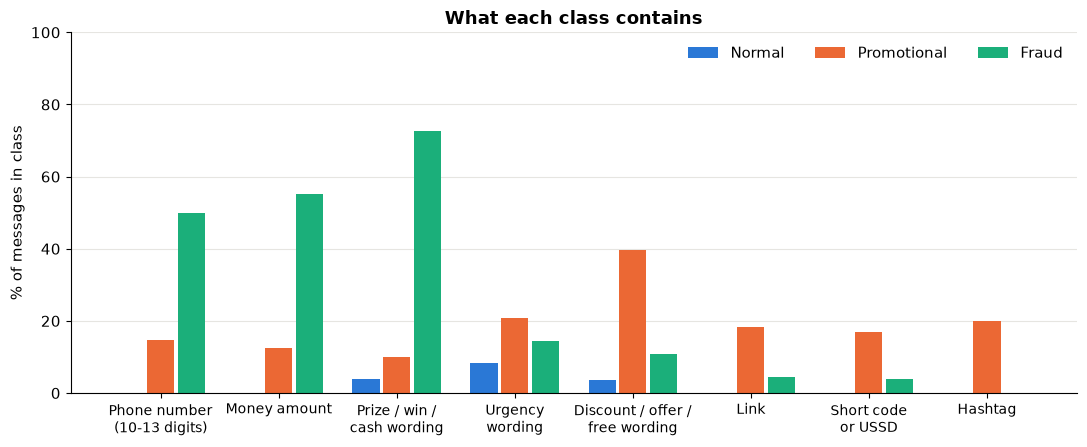

In [18]:
show = {'has_phone': 'Phone number\n(10-13 digits)', 'has_money': 'Money amount', 'has_prize_word': 'Prize / win /\ncash wording',
        'has_urgency': 'Urgency\nwording', 'has_discount': 'Discount / offer /\nfree wording', 'has_url': 'Link',
        'has_shortcode': 'Short code\nor USSD', 'has_hashtag': 'Hashtag'}
x = np.arange(len(show))
w = 0.26
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, l in enumerate(labels):
    ax.bar(x + (i - 1) * w, rates.loc[list(show), l], width=w - 0.03, color=colors[l], label=l)
ax.set_xticks(x)
ax.set_xticklabels(show.values(), fontsize=10)
ax.set_ylabel('% of messages in class')
ax.set_ylim(0, 100)
ax.set_title('What each class contains')
ax.legend(frameon=False, ncol=3, loc='upper right')
ax.grid(axis='x', visible=False)
save('04_pattern_rates')

Prize / lucky draw / winner                   66.1
Benazir Income Support / 8171                 48.1
Asks to call or WhatsApp a number             40.8
Jeeto Pakistan / TV show                      17.7
Bank / ATM / card / account                   15.5
Blocked / suspended / verification             9.3
UK-style premium-rate spam                     7.5
Easypaisa / JazzCash                           1.7
Telecom brand (Telenor, Jazz, Zong, Ufone)     0.7
dtype: float64


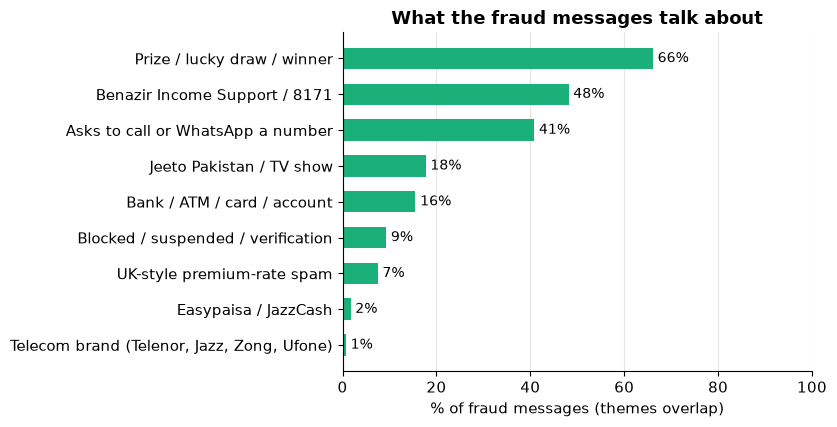

In [19]:
# what the fraud messages are about
themes = {
    'Benazir Income Support / 8171': r'benazir|\bbisp\b|8171',
    'Prize / lucky draw / winner': r'prize|lucky draw|winner|\bwon\b|award',
    'Asks to call or WhatsApp a number': r'\bcall\b|whatsapp|contact',
    'Jeeto Pakistan / TV show': r'jeeto|\bary\b|game show',
    'Bank / ATM / card / account': r'\batm\b|\bbank|\bcard\b|account',
    'Telecom brand (Telenor, Jazz, Zong, Ufone)': r'telenor|jazz|zong|ufone',
    'Easypaisa / JazzCash': r'easypaisa|easy paisa|jazzcash|jazz cash',
    'Blocked / suspended / verification': r'block|suspend|verif|biometric',
    'UK-style premium-rate spam': None,
}
fraud = df[df.label == 'Fraud']
fl = fraud.text.str.lower()
theme_share = pd.Series({k: (fraud.uk_style.mean() if v is None else fl.str.contains(v).mean()) for k, v in themes.items()}).mul(100).sort_values()
print(theme_share.round(1).sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
b = ax.barh(theme_share.index, theme_share.values, color=colors['Fraud'], height=0.6)
for r in b:
    ax.text(r.get_width() + 1, r.get_y() + r.get_height() / 2, f'{r.get_width():.0f}%', va='center', fontsize=10)
ax.set_xlim(0, 100)
ax.set_xlabel('% of fraud messages (themes overlap)')
ax.set_title('What the fraud messages talk about')
ax.grid(axis='y', visible=False)
save('05_fraud_themes')

In [20]:
# brand mentions by class
brands = {'Telenor': 'telenor', 'Jazz': r'\bjazz\b', 'Zong': 'zong', 'Ufone': 'ufone', 'Easypaisa': 'easypaisa|easy paisa',
          'JazzCash': 'jazzcash|jazz cash', 'Benazir/BISP': r'benazir|\bbisp\b', 'Jeeto Pakistan': 'jeeto', 'Daraz': 'daraz',
          'Sapphire': 'sapphire', 'Khaadi': 'khaadi', 'Dawlance': 'dawlance', 'HBL': r'\bhbl\b'}
brand_counts = pd.DataFrame({b: low.str.contains(p).groupby(df.label).sum() for b, p in brands.items()}).T[labels]
brand_counts['total'] = brand_counts.sum(axis=1)
print(brand_counts.sort_values('total', ascending=False))

label           Normal  Promotional  Fraud  total
Benazir/BISP         0            0    527    527
Jeeto Pakistan       0            0    112    112
Zong                 0           60      4     64
Easypaisa            0           43     18     61
Telenor              0           51      3     54
Daraz                0           52      1     53
Ufone                0           45      1     46
Jazz                 0           35      3     38
Sapphire             0           26      0     26
Khaadi               0           16      0     16
Dawlance             0           10      0     10
HBL                  0            0      5      5
JazzCash             0            1      1      2


In [21]:
# phone numbers: how many distinct ones, and how often is one reused (numbers masked in the printout)
nums = digits.str.findall(r'(?<!\d)\+?\d{10,13}(?!\d)')
ph = df.assign(num=nums).explode('num').dropna(subset=['num'])
print('messages with a number:', df.has_phone.sum(), '| distinct numbers:', ph.num.nunique())
print(ph.groupby('label').num.agg(['size', 'nunique']).reindex(labels))
top_nums = ph.groupby('num').agg(messages=('text', 'size'), label=('label', 'first')).sort_values('messages', ascending=False).head(5)
top_nums.index = [n[:2] + 'X' * (len(n) - 2) for n in top_nums.index]
print(top_nums)

# money amounts quoted in fraud messages
amt = fraud.text.str.lower().str.extract(r'(\d[\d,]*)\s*(?:rupees|rs\b|pkr)')[0].dropna().str.replace(',', '').astype(float)
print()
print('fraud messages with "<number> rupees/rs":', len(amt))
print(amt.describe().round(0))

# a lot of the numbers are obvious placeholders with running digits (123456, 987654 ...)
seq = ph.num.str.contains('123456|234567|345678|456789|987654|876543')
print()
print(f'numbers with a running-digit sequence: {ph.num[seq].nunique()} of {ph.num.nunique()} distinct, {seq.mean():.1%} of all number mentions')

messages with a number: 742 | distinct numbers: 483
              size  nunique
label                      
Normal         NaN      NaN
Promotional  205.0     97.0
Fraud        563.0    393.0
             messages        label
03XXXXXXXX         51        Fraud
03XXXXXXXXX        49        Fraud
08XXXXXXXXX        29  Promotional
09XXXXXXXX         21  Promotional
08XXXXXXXXX        13  Promotional

fraud messages with "<number> rupees/rs": 457
count      457.0
mean     29794.0
std      18368.0
min          0.0
25%      19200.0
50%      23500.0
75%      31800.0
max      84500.0
Name: 0, dtype: float64

numbers with a running-digit sequence: 62 of 483 distinct, 12.1% of all number mentions


Half the fraud messages carry a phone number, but the numbers are not a varied real-world set: two numbers
alone account for about 100 fraud messages between them, and a chunk of the rest are placeholder-looking
running digits. That fits the paraphrase story, where the same seed message is reworded with the number
kept or swapped for a made-up one. Some numbers could still belong to real people, so they stay masked here.

## Words and phrases per class

In [22]:
from sklearn.feature_extraction.text import CountVectorizer

# digits collapsed so templates with different amounts count as the same phrase
doc = df.text_norm.str.replace(r'\d+', ' ', regex=True)

def top_terms(ngram, k=12, stop='english'):
    cv = CountVectorizer(ngram_range=(ngram, ngram), stop_words=stop, binary=True, min_df=5)
    M = cv.fit_transform(doc)
    terms = np.array(cv.get_feature_names_out())
    out = {}
    for l in labels:
        idx = (df.label == l).values
        dfreq = np.asarray(M[idx].sum(axis=0)).ravel()
        out[l] = [f'{t} ({c})' for t, c in sorted(zip(terms, dfreq), key=lambda z: -z[1])[:k]]
    return pd.DataFrame(out)

print('most common words (number of messages containing them)')
print(top_terms(1))
print()
print('most common two-word phrases')
print(top_terms(2))

most common words (number of messages containing them)
           Normal       Promotional           Fraud
0       day (327)        sale (219)     prize (576)
1      good (255)     fashion (169)      cash (539)
2      like (220)        send (166)   benazir (524)
3   morning (163)        stop (145)    rupees (523)
4      just (140)        shop (136)   program (482)
5    missed (138)       style (134)   support (464)
6        im (137)         reg (118)    income (461)
7       new (129)  experience (114)  whatsapp (248)
8      time (119)     explore (110)   success (181)
9      life (113)        text (104)     youve (174)
10    night (108)     discover (99)    number (153)
11    calls (105)           rs (94)       atm (122)

most common two-word phrases


                    Normal                   Promotional                  Fraud
0       good morning (137)                send reg (109)   benazir income (461)
1       missed calls (103)             alkaram lawn (71)       cash prize (461)
2           hes going (68)                lawn sale (71)   income support (461)
3   happy anniversary (47)                lets shop (68)  support program (428)
4          day filled (46)          promotions send (56)     prize rupees (427)
5           free time (44)               daraz club (52)   jeeto pakistan (112)
6         wont forget (40)  httpsclickdarazpke dbok (52)          atm card (97)
7         just missed (39)                  ak town (51)          bol game (83)
8         wishing day (38)                town oaks (51)         youve won (68)
9          didnt need (34)          promotional sms (50)   program pleased (67)
10     calls messages (31)             fashion sale (45)        lucky draw (56)
11          cards box (31)              

Normal
   term  in_class_pct  elsewhere_pct  diff
    day          13.1            1.4  11.7
   good          10.2            1.2   9.0
   like           8.8            1.5   7.3
morning           6.6            0.0   6.5
 missed           5.6            0.1   5.4
  night           4.4            0.1   4.2
   life           4.6            0.8   3.8
  going           4.1            0.3   3.7
  happy           3.8            0.1   3.7
     im           5.5            2.0   3.5
   wont           3.6            0.2   3.5
   love           3.8            0.5   3.3

Promotional
      term  in_class_pct  elsewhere_pct  diff
      sale          17.2            0.0  17.2
   fashion          13.3            0.0  13.3
      send          13.1            1.6  11.5
      stop          11.4            0.4  11.0
      shop          10.7            0.1  10.6
     style          10.6            0.1  10.5
       reg           9.3            0.1   9.3
experience           9.0            0.3   8.7
   expl

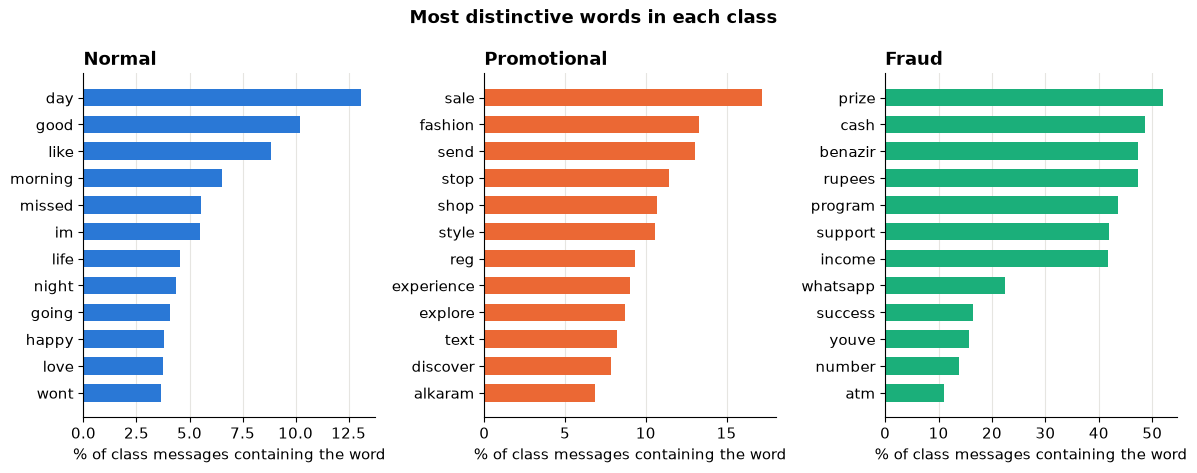

In [23]:
# distinctive words: share of the class's messages containing the word, versus the other two classes
cv = CountVectorizer(stop_words='english', binary=True, min_df=10)
M = cv.fit_transform(doc)
terms = np.array(cv.get_feature_names_out())
dist = {}
for l in labels:
    idx = (df.label == l).values
    p_in = (np.asarray(M[idx].sum(axis=0)).ravel() + 1) / (idx.sum() + 2)
    p_out = (np.asarray(M[~idx].sum(axis=0)).ravel() + 1) / ((~idx).sum() + 2)
    s = pd.DataFrame({'term': terms, 'in_class_pct': p_in * 100, 'elsewhere_pct': p_out * 100, 'diff': (p_in - p_out) * 100})
    dist[l] = s.sort_values('diff', ascending=False).head(12)
    print(l)
    print(dist[l].round(1).to_string(index=False))
    print()

fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))
for ax, l in zip(axes, labels):
    d = dist[l].sort_values('in_class_pct')
    ax.barh(d.term, d.in_class_pct, color=colors[l], height=0.65)
    ax.set_title(l, loc='left')
    ax.set_xlabel('% of class messages containing the word')
    ax.grid(axis='y', visible=False)
fig.suptitle('Most distinctive words in each class', fontweight='bold', fontsize=13)
save('06_distinctive_words')

## Baseline classifier (secondary)

TF-IDF on words and word pairs, logistic regression, on the cleaned text (quotes stripped). Two ways of
splitting:

- a plain stratified 80/20 split
- a grouped split where a whole near-duplicate group goes to either train or test, never both

The second is the honest one. With paraphrase families this large, a random split puts rewordings of the
same message on both sides.

In [24]:
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

def make_model():
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True),
                         LogisticRegression(max_iter=2000, C=5, class_weight='balanced'))

X_text, y, groups = df.text, df.label, df.dup_group

# plain split
tr, te = train_test_split(df.index, test_size=0.2, stratify=y, random_state=42)
leaky = groups[te].isin(set(groups[tr])).mean()
model = make_model().fit(X_text[tr], y[tr])
pred = model.predict(X_text[te])
print(f'random split: test rows {len(te)}, accuracy {accuracy_score(y[te], pred):.3f}, macro F1 {f1_score(y[te], pred, average="macro"):.3f}')
print(f'share of test rows with a near-duplicate in train: {leaky:.1%}')

# grouped split
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
gtr, gte = next(sgkf.split(X_text, y, groups))
gmodel = make_model().fit(X_text.iloc[gtr], y.iloc[gtr])
gpred = gmodel.predict(X_text.iloc[gte])
print(f'grouped split: test rows {len(gte)}, accuracy {accuracy_score(y.iloc[gte], gpred):.3f}, macro F1 {f1_score(y.iloc[gte], gpred, average="macro"):.3f}')
print('overlap of groups between train and test:', len(set(groups.iloc[gtr]) & set(groups.iloc[gte])))
print()
print(classification_report(y.iloc[gte], gpred, labels=labels, digits=3))

random split: test rows 977, accuracy 0.991, macro F1 0.988
share of test rows with a near-duplicate in train: 12.2%


grouped split: test rows 977, accuracy 0.983, macro F1 0.978
overlap of groups between train and test: 0

              precision    recall  f1-score   support

      Normal      0.992     0.998     0.995       500
 Promotional      0.965     0.976     0.971       255
       Fraud      0.981     0.955     0.968       222

    accuracy                          0.983       977
   macro avg      0.980     0.976     0.978       977
weighted avg      0.983     0.983     0.983       977



In [25]:
# 5-fold versions of both, to check the single split isn't a fluke
def cv_scores(splitter, use_groups):
    acc, f1 = [], []
    for a, b in splitter.split(X_text, y, groups if use_groups else None):
        p = make_model().fit(X_text.iloc[a], y.iloc[a]).predict(X_text.iloc[b])
        acc.append(accuracy_score(y.iloc[b], p)); f1.append(f1_score(y.iloc[b], p, average='macro'))
    return np.mean(acc), np.mean(f1), np.min(f1)

for name, sp, g in [('random 5-fold', StratifiedKFold(5, shuffle=True, random_state=42), False),
                    ('grouped 5-fold', StratifiedGroupKFold(5, shuffle=True, random_state=42), True)]:
    a, f, fmin = cv_scores(sp, g)
    print(f'{name}: mean accuracy {a:.3f}, mean macro F1 {f:.3f}, worst-fold macro F1 {fmin:.3f}')

# how far do the formatting artefacts alone get you? (raw text features only, no words)
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
art = df[['was_quoted', 'n_chars']].astype(float)
print('majority-class accuracy:', round(y.value_counts(normalize=True).max(), 3))
print('quote mark + length only, depth-3 tree, 5-fold accuracy:',
      round(cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=0), art, y, cv=StratifiedKFold(5, shuffle=True, random_state=42)).mean(), 3))

random 5-fold: mean accuracy 0.983, mean macro F1 0.979, worst-fold macro F1 0.967


grouped 5-fold: mean accuracy 0.983, mean macro F1 0.978, worst-fold macro F1 0.977
majority-class accuracy: 0.512


quote mark + length only, depth-3 tree, 5-fold accuracy: 0.81


                  pred Normal  pred Promotional  pred Fraud
true Normal               499                 1           0
true Promotional            2               249           4
true Fraud                  2                 8         212


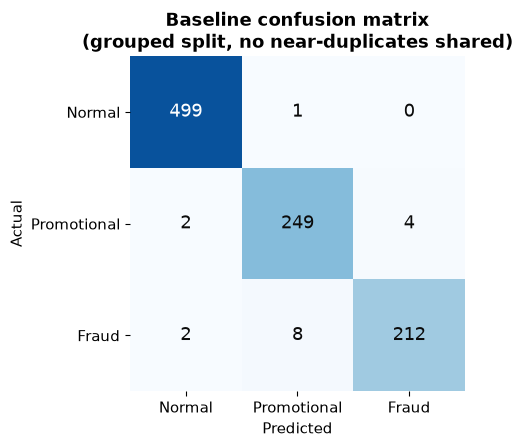

In [26]:
cm = confusion_matrix(y.iloc[gte], gpred, labels=labels)
print(pd.DataFrame(cm, index=[f'true {l}' for l in labels], columns=[f'pred {l}' for l in labels]))

fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.max() * 1.15)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{cm[i, j]}', ha='center', va='center', fontsize=13,
                color='white' if cm[i, j] > cm.max() * 0.55 else '#0b0b0b')
ax.set_xticks(range(3)); ax.set_xticklabels(labels)
ax.set_yticks(range(3)); ax.set_yticklabels(labels)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title('Baseline confusion matrix\n(grouped split, no near-duplicates shared)')
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
save('07_confusion_matrix')

In [27]:
# the mistakes on the grouped test set
miss = df.iloc[gte].assign(pred=gpred)
miss = miss[miss.label != miss.pred]
print(len(miss), 'misclassified')
print(miss.groupby(['label', 'pred']).size())
miss[['label', 'pred', 'text']].assign(text=lambda d: d.text.map(mask).str[:150]).head(12)

17 misclassified
label        pred       
Fraud        Normal         2
             Promotional    8
Normal       Promotional    1
Promotional  Fraud          4
             Normal         2
dtype: int64


,label,pred,text
30,Fraud,Promotional,Enter your information on the given link to win a Kisan Bhai mobile phone. Thank you https://bit.ly/3FYy3Ey
32,Fraud,Promotional,"In jazz study welcome! here you will get the lectures from classes 1- 12, including short courses, language learning, and much morefor free just by do"
101,Fraud,Promotional,"The zong Telecom numbers ending 9167 are selected to receive a Rs.2,00,000 award. If you have a match please call XXXXXXXXXX quoting claim code 5001 s"
123,Fraud,Promotional,Talk sexy!! Make new friends or fall in love in the worlds most discreet text dating service. Just text VIP to 83110 and see who you could meet. AND G
131,Fraud,Normal,"Solve d Case : A Man Was Found Murdered On 19 october, AfterNoon. 1,His wife called Police. 2,Police questioned everyone. 3,Wife: Sir,I was sleeping,"
140,Fraud,Promotional,"Last Chance! Claim ur £150 worth of discount vouchers today! Text SHOP to 85023 now! SavaMob, offers mobile! T Cs SavaMob POBOX84, M263UZ. £3.00 Sub."
141,Fraud,Promotional,You have an outstanding tax refund of 578.44G8P for the tax year 15/16. Please fill out the following form to process your refund http:///hmrc.taxreba
149,Fraud,Promotional,UR GOING 2 BAHAMAS! CallFREEFONE XXXXXXXXXXX and speak to a live operator to claim either Bahamas cruise of£2000 CASH 18+only. To opt out txt X to XXX
191,Fraud,Promotional,U XXXXXXXXXXXX have a secret admirer who is looking 2 make contact with U-find out who they R*reveal who thinks UR so special-call on XXXXXXXXXXX
206,Fraud,Normal,"Win the newest “Harry Potter and the Order of the Phoenix (Book 5) reply HARRY, answer 5 questions - chance to be the first among readers!"


In [28]:
# strongest words per class in the fitted model
tf, lr = gmodel.named_steps['tfidfvectorizer'], gmodel.named_steps['logisticregression']
names = np.array(tf.get_feature_names_out())
for i, l in enumerate(lr.classes_):
    top = np.argsort(lr.coef_[i])[::-1][:12]
    print(l, '->', ', '.join(names[top]))

Fraud -> prize, cash, rupees, benazir, urgent, whatsapp, at, 000, call, your, program, card
Normal -> my, day, missed, night, morning, like, life, good, ll, happy, do you, with you
Promotional -> fashion, sale, shop, 4g, up to, stop, with, experience, text, style, with our, shopping


The classes separate very easily, and the grouped split barely dents the score. This mostly reflects how
different the three sets of text are in style and vocabulary: chatty one-liners, brand adverts and
prize/aid scams. It does not mean SMS fraud detection is easy. Even the quote mark plus
message length gets most of the way there on the raw file. A model trained on this would not necessarily
hold up on real SMS traffic, and it has seen no Urdu or Roman Urdu at all.

The errors are telling too. Most of the misses are UK-style spam that sits under Fraud in one place and
Promotional in another, where the line between the two labels looks arbitrary.

## Highest / lowest / most

In [29]:
longest = df.loc[df.n_chars.idxmax()]
shortest = df.loc[df.n_chars.idxmin()]
biggest = df.groupby('dup_group').size().sort_values(ascending=False)
top_skel = df.groupby('skeleton').size().sort_values(ascending=False)

facts = [
    f"Largest class: Normal, {counts['Normal']:,} messages ({share['Normal']}%). Smallest: Fraud, {counts['Fraud']:,} ({share['Fraud']}%).",
    f"Longest message: {longest.n_chars} characters ({longest.label}). Shortest: {shortest.n_chars} characters ({shortest.label}): '{mask(shortest.text)}'.",
    f"Median length: Normal {df[df.label=='Normal'].n_chars.median():.0f}, Promotional {df[df.label=='Promotional'].n_chars.median():.0f}, Fraud {df[df.label=='Fraud'].n_chars.median():.0f} characters.",
    f"Most templated class: Fraud, {near.loc['Fraud','mean']*100:.1f}% of messages sit in a near-duplicate group (Normal {near.loc['Normal','mean']*100:.1f}%, Promotional {near.loc['Promotional','mean']*100:.1f}%).",
    f"Largest near-duplicate group: {biggest.iloc[0]} messages ({df[df.dup_group==biggest.index[0]].label.iloc[0]}).",
    f"Most reused wording with only the number changed: {top_skel.iloc[0]} messages.",
    f"Most common fraud theme: Benazir Income Support Programme / 8171, in {fl.str.contains(themes['Benazir Income Support / 8171']).mean()*100:.1f}% of fraud messages.",
    f"Phone numbers: {rates.loc['has_phone','Fraud']}% of fraud messages carry one, against {rates.loc['has_phone','Promotional']}% of promotional and {rates.loc['has_phone','Normal']}% of normal.",
    f"Most reused phone number appears in {top_nums.messages.iloc[0]} messages ({top_nums.label.iloc[0]}); {ph.num.nunique()} distinct numbers overall.",
    f"Links: {rates.loc['has_url','Promotional']}% of promotional messages, {rates.loc['has_url','Fraud']}% of fraud, {rates.loc['has_url','Normal']}% of normal.",
    f"Largest rupee amount quoted in a fraud message: {amt.max():,.0f}; median {amt.median():,.0f}.",
    f"Most mentioned brand: {brand_counts.total.idxmax()} ({brand_counts.total.max()} messages).",
    f"Quote-wrapped in the raw file: {src.loc['Normal','was_quoted']}% of Normal, {src.loc['Promotional','was_quoted']}% of Promotional, {src.loc['Fraud','was_quoted']}% of Fraud.",
]
for f in facts:
    print('-', f)

- Largest class: Normal, 2,501 messages (51.2%). Smallest: Fraud, 1,107 (22.7%).
- Longest message: 582 characters (Promotional). Shortest: 12 characters (Normal): '26th OF JULY'.
- Median length: Normal 71, Promotional 155, Fraud 144 characters.
- Most templated class: Fraud, 40.4% of messages sit in a near-duplicate group (Normal 6.8%, Promotional 4.8%).
- Largest near-duplicate group: 13 messages (Fraud).
- Most reused wording with only the number changed: 13 messages.
- Most common fraud theme: Benazir Income Support Programme / 8171, in 48.1% of fraud messages.
- Phone numbers: 50.0% of fraud messages carry one, against 14.7% of promotional and 0.0% of normal.
- Most reused phone number appears in 51 messages (Fraud); 483 distinct numbers overall.
- Links: 18.4% of promotional messages, 4.5% of fraud, 0.0% of normal.
- Largest rupee amount quoted in a fraud message: 84,500; median 23,500.
- Most mentioned brand: Benazir/BISP (527 messages).
- Quote-wrapped in the raw file: 91.2% o

## Findings

- Three classes, moderately imbalanced: about half Normal, a quarter Promotional, a bit under a quarter Fraud.
- The data is a blend, not a clean sample of Pakistani SMS. Part looks like an older UK/Singapore-style
  English spam corpus, part is Pakistan-specific scam and promo text, and a large part is LLM-written
  paraphrase (two chatbot replies were left in the file as rows).
- Everything is in English. No Urdu script and effectively no Roman Urdu.
- Fraud is heavily templated: 40% of fraud rows are a close rewording of another fraud row, and the Benazir
  Income Support cash-prize story alone covers nearly half the class.
- Most fraud messages use prize or cash wording, and about half carry a phone number and a money amount. Promotional
  messages lean on discounts, links, hashtags and short codes. Normal messages have almost none of these.
- A simple TF-IDF + logistic regression model separates the classes almost perfectly, even when
  near-duplicates are kept on one side of the split.

## Limitations

- Provenance is not documented. The "looks like a legacy corpus" and "looks LLM-written" calls are
  judgements from reading the text and from the artefacts, not something the file states.
- The near-duplicate grouping uses a 0.8 cosine threshold. It catches rewordings that share most words; looser
  paraphrases of the same idea are not grouped, so some leakage across the split probably remains.
- The pattern flags are regular expressions and will have some false hits and misses.
- Classifier scores describe this file only. They are not evidence about performance on real SMS traffic.
- There are no timestamps, senders or recipients, so nothing can be said about timing or campaigns.

## Save cleaned data

In [30]:
out_cols = ['label', 'text', 'clean_message', 'was_quoted', 'n_chars', 'n_words', 'dup_group', 'in_near_dup_group',
            'uk_style', 'pk_marker'] + flags
out = df[out_cols].rename(columns={'text': 'message', 'clean_message': 'original_clean_message', 'dup_group': 'near_dup_group'})
out.to_csv('sms_cleaned.csv', index=False)
print(out.shape)
print(sorted(p.name for p in Path('charts').glob('*.png')))

(4884, 20)
['01_label_counts.png', '02_length_by_class.png', '03_provenance_markers.png', '04_pattern_rates.png', '05_fraud_themes.png', '06_distinctive_words.png', '07_confusion_matrix.png']
